# Grafici per la presentazione

Corner plot ridotti ai **soli parametri di DM e scattering** ($\gamma_{\rm DM}$, $\log_{10}A_{\rm DM}$, $\gamma_{\rm SV}$, $\log_{10}A_{\rm SV}$),
con etichette grandi, per essere leggibili sul proiettore.

Stesse catene, stessi colori e stesse impostazioni del notebook `23_Grafici_tesi.ipynb`: legge solo catene già salvate, **nessun sampling**.
Le figure vanno in `Presentazione/Figure/`; le figure della tesi non vengono toccate.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import corner

CARTELLA = 'Presentazione/Figure'
os.makedirs(CARTELLA, exist_ok=True)

REALE   = '#2E86AB'   # blu: dati reali
SIM     = '#F4A261'   # arancio: simulazioni
SIM_2   = '#6A4C93'   # viola: seconda simulazione
VERO    = '#222222'   # valori iniettati

In [2]:
def load_chain(path):
    c = np.loadtxt(path)[:, :-4]
    return c[len(c)//4:]           # rimuovo il 25% di burn-in (come nel notebook 23)

# ordine delle colonne delle catene a 6 parametri (lo stesso del notebook 23)
params_6 = ['J1640+2224_dm_gp_gamma', 'J1640+2224_dm_gp_log10_A',
            'J1640+2224_red_noise_gamma', 'J1640+2224_red_noise_log10_A',
            'J1640+2224_sv_gp_gamma', 'J1640+2224_sv_gp_log10_A']

# parametri mostrati nelle slide: solo DM e scattering
params_slide = ['J1640+2224_dm_gp_gamma', 'J1640+2224_dm_gp_log10_A',
                'J1640+2224_sv_gp_gamma', 'J1640+2224_sv_gp_log10_A']
colonne = [params_6.index(p) for p in params_slide]

# valori iniettati nelle simulazioni (gli stessi del notebook 23)
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}

pretty_labels = {
    'J1640+2224_dm_gp_gamma': r'$\gamma_{\rm DM}$',
    'J1640+2224_dm_gp_log10_A': r'$\log_{10}A_{\rm DM}$',
    'J1640+2224_sv_gp_gamma': r'$\gamma_{\rm SV}$',
    'J1640+2224_sv_gp_log10_A': r'$\log_{10}A_{\rm SV}$',
}
etichette = [pretty_labels[p] for p in params_slide]

In [3]:
def corner_slide(catene, colori, nome, iniettati=False):
    """Corner a 4 parametri (DM e scattering) con una o più catene sovrapposte.
    catene: lista di catene a 6 parametri; colori: lista di colori (il primo è sotto).
    iniettati=True disegna le linee nere dei valori iniettati."""
    opzioni = dict(
        labels=etichette,
        show_titles=False,
        label_kwargs={'fontsize': 18},
        plot_datapoints=False,
        fill_contours=True,
        levels=(0.68, 0.95, 0.997),
        smooth=1.0,
        smooth1d=None,
        bins=40,
        max_n_ticks=3,
        labelpad=0.25,
    )
    fig = None
    for k, (c, col) in enumerate(zip(catene, colori)):
        extra = {}
        if k == 0 and iniettati:
            extra = dict(truths=[truths_dict[p] for p in params_slide], truth_color=VERO)
        fig = corner.corner(
            c[:, colonne],
            color=col,
            hist_kwargs={'color': col, 'linewidth': 2, 'density': True},
            fig=fig,
            **({} if k == 0 else {'scale_hist': False}),
            **opzioni, **extra,
        )
    for ax in fig.axes:
        ax.tick_params(labelsize=13)
    fig.set_size_inches(6, 6)
    fig.savefig(f'{CARTELLA}/{nome}.pdf', bbox_inches='tight')
    fig.savefig(f'{CARTELLA}/{nome}.png', dpi=150, bbox_inches='tight')
    return fig

## Catene (le stesse del notebook 23)

In [4]:
chain_reali       = load_chain('./test/chain_1.txt')                 # dati reali DR2low, alpha = 4.0
chain_reali_44    = load_chain('./test_real_sv44/chain_1.txt')       # dati reali, alpha = 4.4
chain_sim         = load_chain('./test_sim/chain_1.txt')             # simulazione di riferimento
chain_sim2        = load_chain('./test_sim2/chain_1.txt')            # riferimento per il GWB
chain_gwb_A145    = load_chain('./test_sim_gwb_A145/chain_1.txt')    # GWB log10_A = -14.5
chain_bn_off      = load_chain('./test_sim_bn_OFF_50comp/chain_1.txt')   # senza band noise (alpha = 4.4)
chain_bn125       = load_chain('./test_sim_bn_A125_50comp/chain_1.txt')  # band noise -12.5, 6 par
chain_gwbbn125    = load_chain('./test_sim_bn_A125_GWB_iniezione_unica_6par/chain_1.txt')  # GWB -14 + band -12.5

## Slide 6 — degenerazione nei dati reali (solo blu)

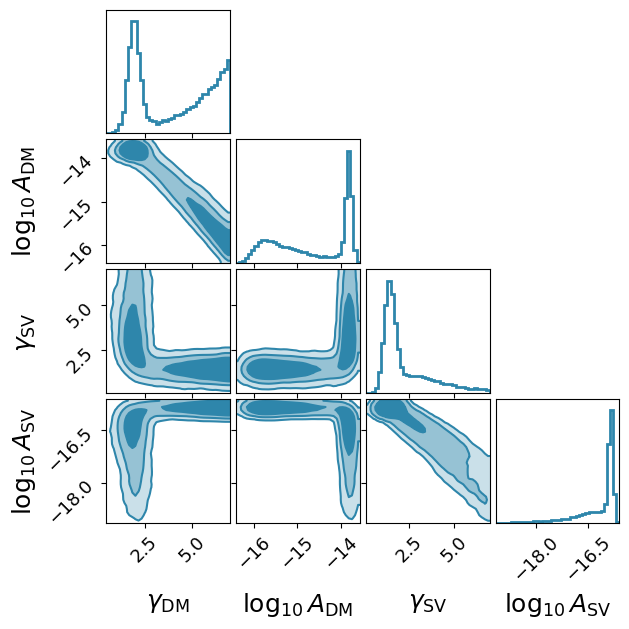

In [5]:
corner_slide([chain_reali], [REALE], 'P06_reali_DM_SV');

## Slide 8 — dati reali vs simulazione di riferimento

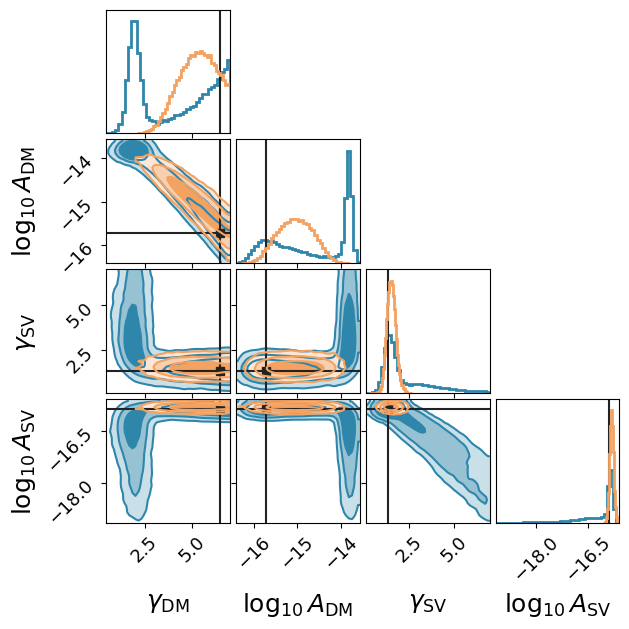

In [6]:
corner_slide([chain_reali, chain_sim], [REALE, SIM], 'P08_reali_vs_sim_DM_SV', iniettati=True);

## Slide 9 — band noise non modellato (-12.5) vs senza band noise

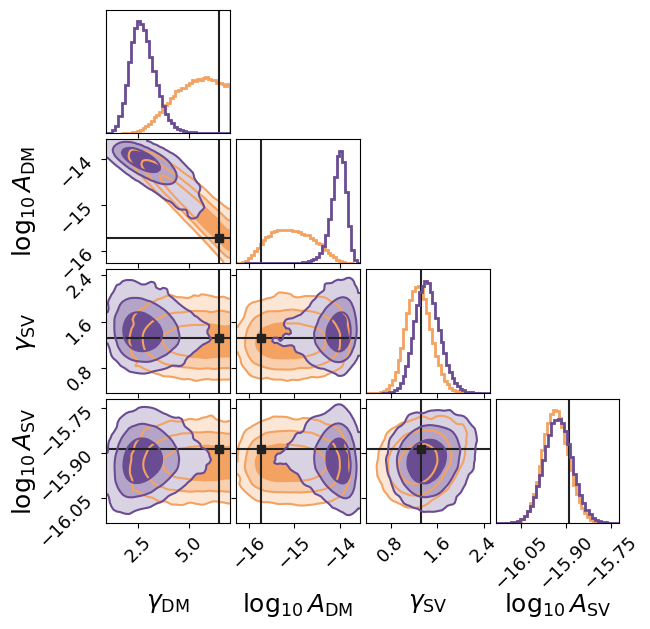

In [7]:
corner_slide([chain_bn_off, chain_bn125], [SIM, SIM_2], 'P09_bn_OFF_vs_A125_DM_SV', iniettati=True);

## Riserva — GWB a -14.5 vs simulazione di riferimento

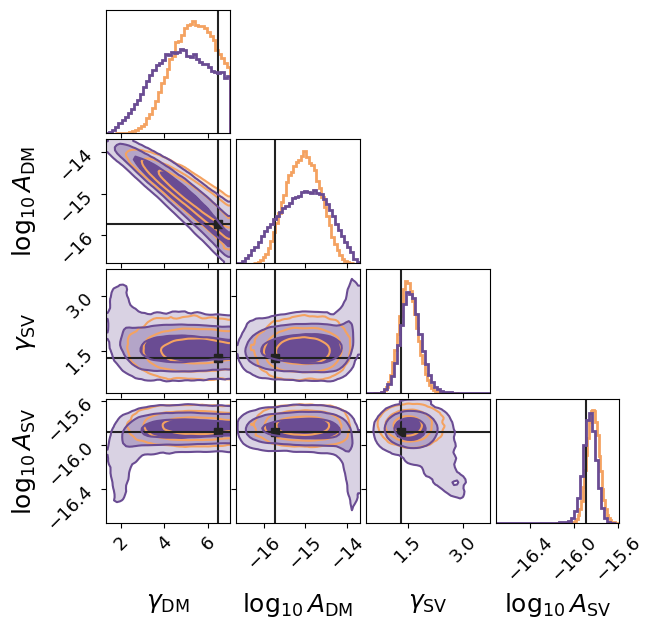

In [8]:
corner_slide([chain_sim2, chain_gwb_A145], [SIM, SIM_2], 'R_sim_vs_gwb_A145_DM_SV', iniettati=True);

## Riserva — dati reali (alpha = 4.4) vs GWB -14 + band noise -12.5

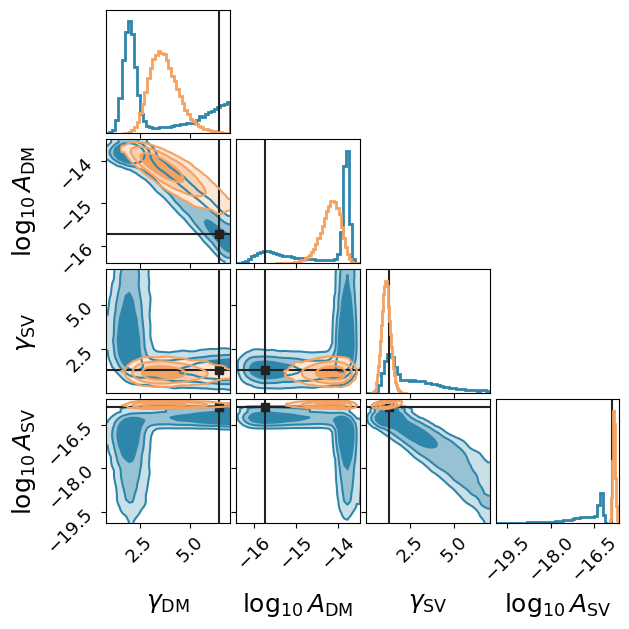

In [9]:
corner_slide([chain_reali_44, chain_gwbbn125], [REALE, SIM], 'R_reali_vs_gwb_bn125_DM_SV', iniettati=True);

## Corner con il band noise nel modello (8 parametri)

Catene a 8 parametri: ordine delle colonne `params_8` = band noise ($\gamma_{\rm BN}$, $\log_{10}A_{\rm BN}$) + i 6 parametri di sempre (come nel notebook 23).
Tutte con $\alpha = 4.4$, nel modello e nelle simulazioni.

In [ ]:
params_8 = ['J1640+2224_band_noise_gamma', 'J1640+2224_band_noise_log10_A'] + params_6
pretty_labels['J1640+2224_band_noise_gamma'] = r'$\gamma_{\rm BN}$'
pretty_labels['J1640+2224_band_noise_log10_A'] = r'$\log_{10}A_{\rm BN}$'

def corner_8par(catene, colori, nome, parametri):
    """Corner di un sottoinsieme 'parametri' di catene a 8 parametri, una o più catene sovrapposte."""
    col_idx = [params_8.index(p) for p in parametri]
    opzioni = dict(
        labels=[pretty_labels[p] for p in parametri],
        show_titles=False, label_kwargs={'fontsize': 18},
        plot_datapoints=False, fill_contours=True, levels=(0.68, 0.95, 0.997),
        smooth=1.0, smooth1d=None, bins=40, max_n_ticks=3, labelpad=0.25,
    )
    fig = None
    for k, (c, col) in enumerate(zip(catene, colori)):
        fig = corner.corner(c[:, col_idx], color=col, fig=fig,
                            hist_kwargs={'color': col, 'linewidth': 2, 'density': True},
                            **({} if k == 0 else {'scale_hist': False}), **opzioni)
    for ax in fig.axes:
        ax.tick_params(labelsize=13)
    n = len(parametri)
    fig.set_size_inches(3 * n if n > 2 else 5, 3 * n if n > 2 else 5)
    fig.savefig(f'{CARTELLA}/{nome}.pdf', bbox_inches='tight')
    fig.savefig(f'{CARTELLA}/{nome}.png', dpi=150, bbox_inches='tight')
    return fig

chain_reali_8par = load_chain('./test_real_bn_bnmodel/chain_1.txt')      # dati reali, 8 par
chain_bn125_8par = load_chain('./test_sim_bn_A125_bnmodel/chain_1.txt')  # sim band noise -12.5, 8 par
chain_bn120_8par = load_chain('./test_sim_bn_A120_bnmodel/chain_1.txt')  # sim band noise -12, 8 par

## Slide 7 — dati reali, modello a 8 parametri (Fig. 5.3 ridotta): band noise e DM

In [ ]:
corner_8par([chain_reali_8par], [REALE], 'P07_reali_8par_BN_DM',
            ['J1640+2224_band_noise_gamma', 'J1640+2224_band_noise_log10_A',
             'J1640+2224_dm_gp_gamma', 'J1640+2224_dm_gp_log10_A']);

## Slide 10 — parametri del band noise: dati reali vs simulazioni a -12.5 (non rivelato) e -12 (rivelato)

In [ ]:
corner_8par([chain_reali_8par, chain_bn125_8par, chain_bn120_8par], [REALE, SIM, SIM_2],
            'P10_BN_reali_vs_sim',
            ['J1640+2224_band_noise_gamma', 'J1640+2224_band_noise_log10_A']);

## Slide 10 (alternativa più leggibile) — solo $\log_{10}A_{\rm BN}$, posterior 1D

Linee tratteggiate: ampiezze iniettate nelle due simulazioni.

In [ ]:
iA = params_8.index('J1640+2224_band_noise_log10_A')
bins = np.linspace(-20, -11, 61)          # tutto il prior di log10_A_BN

fig, ax = plt.subplots(figsize=(6.5, 4))
for c, col, nome in [(chain_reali_8par, REALE, 'Dati reali'),
                     (chain_bn125_8par, SIM,   r'Simulazione, $-12.5$ (non rivelato)'),
                     (chain_bn120_8par, SIM_2, r'Simulazione, $-12$ (rivelato)')]:
    ax.hist(c[:, iA], bins=bins, density=True, histtype='step', lw=2.5, color=col, label=nome)
ax.axvline(-12.5, color=SIM,   ls='--', lw=1.5)
ax.axvline(-12.0, color=SIM_2, ls='--', lw=1.5)
ax.set_xlabel(r'$\log_{10}A_{\rm BN}$', fontsize=18)
ax.set_ylabel('Densità di probabilità', fontsize=15)
ax.set_xlim(-20, -11)
ax.tick_params(labelsize=13)
ax.legend(frameon=False, fontsize=12, loc='upper left')
fig.tight_layout()
fig.savefig(f'{CARTELLA}/P10_logA_BN_1D.pdf')
fig.savefig(f'{CARTELLA}/P10_logA_BN_1D.png', dpi=150)

## Slide 9 unificata (correzioni di Irene, 23/11): dati reali (blu), simulazione di riferimento (arancio), nuova simulazione (viola)

Stessi 4 parametri (DM e scattering). Linee nere: valori iniettati del rumore.
- GWB: dati reali con alpha = 4 (`test`), riferimento alpha = 4 (`test_sim2`), GWB -14.5 (`test_sim_gwb_A145`)
- Band noise e GWB + band noise: simulazioni con alpha = 4.4, quindi dati reali analizzati con alpha = 4.4 (`test_real_sv44`) e riferimento senza band noise (`test_sim_bn_OFF_50comp`)

In [ ]:
chain_reali_44  = load_chain('./test_real_sv44/chain_1.txt')
chain_gwbbn125  = load_chain('./test_sim_bn_A125_GWB_iniezione_unica_6par/chain_1.txt')

corner_slide([chain_reali, chain_sim2, chain_gwb_A145], [REALE, SIM, SIM_2],
             'P09_1_GWB', iniettati=True)
corner_slide([chain_reali_44, chain_bn_off, chain_bn125], [REALE, SIM, SIM_2],
             'P09_2_band', iniettati=True)
corner_slide([chain_reali_44, chain_bn_off, chain_gwbbn125], [REALE, SIM, SIM_2],
             'P09_3_GWB_band', iniettati=True);

## Slide 11 (correzioni di Irene, 23/11): posterior di $\log_{10}A_{\rm BN}$, dati reali (blu) vs simulazione (viola), due pannelli: iniezione a -12.5 e a -12

In [ ]:
iA = params_8.index('J1640+2224_band_noise_log10_A')
bins = np.linspace(-20, -11, 61)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax, c_sim, A_inj, testo in [(axes[0], chain_bn125_8par, -12.5, 'non rivelato'),
                                (axes[1], chain_bn120_8par, -12.0, 'rivelato')]:
    ax.hist(chain_reali_8par[:, iA], bins=bins, density=True, histtype='step', lw=2.5,
            color=REALE, label='Dati reali')
    ax.hist(c_sim[:, iA], bins=bins, density=True, histtype='step', lw=2.5,
            color=SIM_2, label='Simulazione')
    ax.set_title(f'Iniettato ${A_inj:g}$: {testo}', fontsize=15)
    ax.axvline(A_inj, color=SIM_2, ls='--', lw=1.5)
    ax.set_xlabel(r'$\log_{10}A_{\rm BN}$', fontsize=18)
    ax.set_xlim(-20, -11)
    ax.tick_params(labelsize=13)
    ax.legend(frameon=False, fontsize=12, loc='upper left')
axes[0].set_ylabel('Densità di probabilità', fontsize=15)
fig.tight_layout()
fig.savefig(f'{CARTELLA}/P11_logA_BN_due_pannelli.pdf')
fig.savefig(f'{CARTELLA}/P11_logA_BN_due_pannelli.png', dpi=150)